# Pop-in detection and distributions

Analyze loading curves from an MTS workbook using PopIn's detection criteria and a Weibull CDF fit. Run the cells in order and inspect the detected events: a detected peak is not necessarily a physical pop-in.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# Supports launching Jupyter from the repository root or the python folder.
python_dir = Path.cwd() if Path.cwd().name == 'python' else Path.cwd() / 'python'
sys.path.insert(0, str(python_dir.resolve()))
from popin_analysis import load_curves, detect_popins, weibull_fit


## Settings

The defaults match the GUI's criterion 2 and delta `max - 2*mean`. Criteria 1-3 are padded displacement differences; 4-6 are derivative-based. Change `delta_mean_factor` to 2, 1, 0.5 or 0 to select the corresponding GUI delta. The sample workbook is in nm and mN. Verify the units in your own workbook and update the axis labels below.

In [2]:
workbook = python_dir.parent / 'indentation_data' / 'mts-XP_Indcon5um_Al2O3-40nm.xls'
end_segment = 'Hold Segment Type'  # included as the final loading sample
min_depth, max_depth = None, None  # inclusive lower, exclusive upper; None disables cropping
criterion = 2
delta_mean_factor = 2
event_number = 1  # 1 or 2
critical_parameter = 'load'  # 'load' or 'depth'
depth_unit, load_unit = 'nm', 'mN'


## Load curves and detect events

Each worksheet must have Segment, Displacement and Load columns with two header rows and exactly one selected end-segment marker. A positive peak is confirmed only after the signal drops by more than delta. Sample indices are zero-based after cleaning and cropping. Non-finite derivative values and invalid deltas stop execution so settings can be corrected.

In [3]:
curves = load_curves(workbook, end_segment, min_depth, max_depth)
events = detect_popins(curves, criterion, delta_mean_factor, event_number)
missing = events[events['sample_index'].isna()]
print(f'{len(curves)} curves; {len(missing)} without event {event_number}.')
if not missing.empty:
    print('Curves without the requested event are excluded from the fit:', ', '.join(missing['sheet']))
display(events)


50 curves; 0 without event 1.


,sheet,peak_count,delta,sample_index,depth,load
0,Test 049,2,4.544735,147,7.564449,0.059458
1,Test 047,12,1.178807,15,0.736157,0.002884
2,Test 046,7,1.900443,146,11.133258,0.058935
3,Test 044,5,1.512514,143,6.149690,0.056659
4,Test 042,1,9.675009,204,11.510232,0.120642
5,Test 040,1,5.702793,206,13.260056,0.121846
6,Test 039,8,1.230447,131,8.792817,0.047922
7,Test 038,2,4.223673,127,12.095986,0.044629
8,Test 036,6,1.591003,181,17.306788,0.089587
9,Test 035,8,1.299779,102,7.463040,0.030981


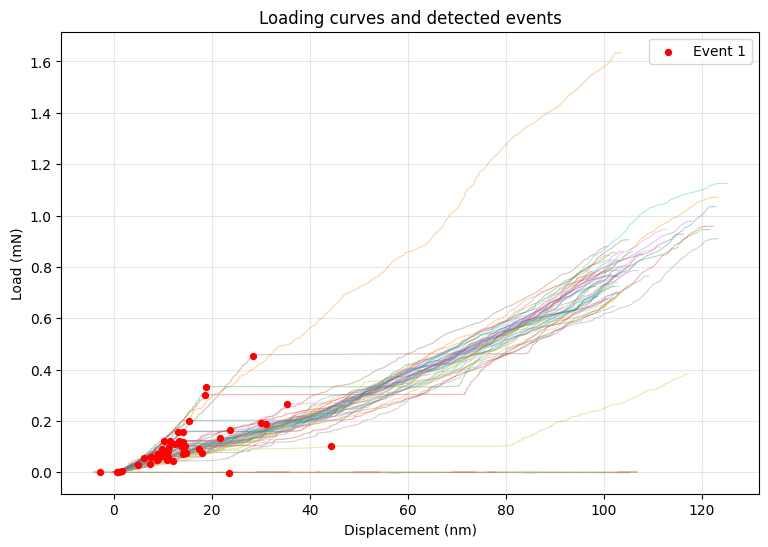

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, curve in curves.items():
    ax.plot(curve['depth'], curve['load'], alpha=0.35, linewidth=0.8)
detected = events.dropna(subset=['sample_index'])
ax.scatter(detected['depth'], detected['load'], color='red', s=18, label=f'Event {event_number}', zorder=3)
ax.set(xlabel=f'Displacement ({depth_unit})', ylabel=f'Load ({load_unit})', title='Loading curves and detected events')
ax.legend()
ax.grid(alpha=0.3)
plt.show()


## Weibull cumulative distribution

The fit uses the MATLAB toolbox's empirical plotting positions and least-squares Weibull CDF. The scale is a fitted parameter, not the arithmetic mean. Only curves with a detected event and a positive critical value are fitted; excluded curves are reported below. Exclusions can bias the distribution, particularly when events are missing or detected during initial contact. Check individual curves and detection settings before interpreting the result. Modified Weibull, Mason, survival and Hertz models are not implemented here.

Excluded nonpositive critical values from the Weibull fit:


,sheet,depth,load
12,Test 031,23.458345,-0.000725


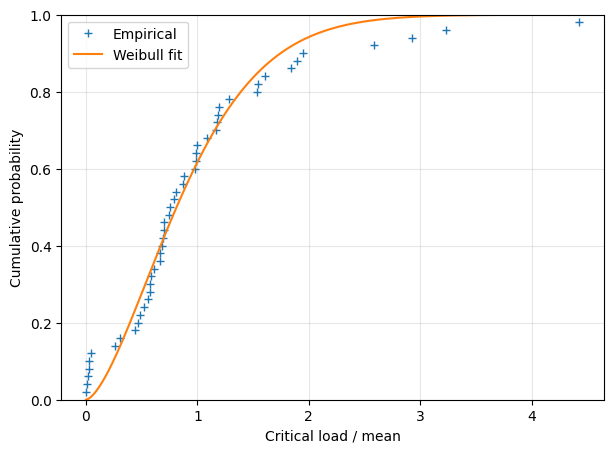

Weibull modulus: 1.57; scale: 0.1051 mN; mean: 0.1024 mN


In [5]:
if critical_parameter not in ('load', 'depth'):
    raise ValueError("critical_parameter must be 'load' or 'depth'")
invalid = detected[detected[critical_parameter] <= 0]
if not invalid.empty:
    print('Excluded nonpositive critical values from the Weibull fit:')
    display(invalid[['sheet', 'depth', 'load']])
fit_events = detected[detected[critical_parameter] > 0]
values, probability, (shape, scale) = weibull_fit(fit_events[critical_parameter])
x = np.linspace(0, values.max(), 300)
fitted = -np.expm1(-(x / scale) ** shape)
unit = load_unit if critical_parameter == 'load' else depth_unit
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(values / values.mean(), probability, '+', label='Empirical')
ax.plot(x / values.mean(), fitted, label='Weibull fit')
ax.set(xlabel=f'Critical {critical_parameter} / mean', ylabel='Cumulative probability', ylim=(0, 1))
ax.grid(alpha=0.3)
ax.legend()
plt.show()
print(f'Weibull modulus: {shape:.4g}; scale: {scale:.4g} {unit}; mean: {values.mean():.4g} {unit}')
